# The training pipeline of a VLA, step by step 🏋️
### Behaviour cloning, covariate shift, DAgger, pre-training, data scale and data quality

**Code:** `src/Halo_VLA/vla_foundations/training.py` (`narrow_start_demos`, `dagger_episodes`, `perturbed_expert_episodes`, `state_action_error`, `ReplayMixture`) on top of `open_vlas` ·
**papers:** DAgger ([Ross et al., 2011](https://arxiv.org/abs/1011.0686)), DART ([Laskey et al., 2017](https://arxiv.org/abs/1703.09327)), ACT ([2304.13705](https://arxiv.org/abs/2304.13705)), Open X-Embodiment ([2310.08864](https://arxiv.org/abs/2310.08864)), OpenVLA ([2406.09246](https://arxiv.org/abs/2406.09246)).

Almost every VLA is trained with the same recipe: **initialise from a pre-trained VLM, pre-train on a large mixture of robot data, then fine-tune on the target task**, always with the same supervised objective, *behaviour cloning* (BC). This notebook takes the recipe apart in a toy world and *measures* the three things the interview questions probe:

| part | question | experiment |
|---|---|---|
| 1 | what is BC, and **why does it fail** at test time? | covariate shift made visible; the compounding error; DAgger, noise-injected data and chunking as fixes |
| 2 | what does **pre-training** buy, and how does **data scale** matter? | success vs number of demonstrations, from scratch vs a pre-trained VLM |
| 3 | is the bottleneck the **amount** or the **quality** of the data? | clean vs mixed-quality demonstrations |

### Where this notebook corrects the usual summary
* The usual summary gives **demo counts** ("50-100K demos = task-specific fine-tune, 800K+ = generalist") that do not match the papers: OpenVLA is **fine-tuned on ~10-150 demonstrations** per task and was **pre-trained on ≈ 970K episodes** of Open X-Embodiment; Octo on ≈ 800K. Numbers quoted at the end (Step 8) come from the papers.
* **Open X-Embodiment** is **60 datasets** from 21 institutions covering **22 robot embodiments** and > 1M trajectories (527 skills), not "22 datasets".
* BC is *not* "minimise MSE" by definition: it is *maximum likelihood* of the expert's actions given the observation. MSE is the special case of a fixed-variance Gaussian policy (Step 1), and it is exactly what fails on multimodal demonstrations (see `action_representations_step_by_step.ipynb`).

| | published | this notebook |
|---|---|---|
| pre-training data | 970K episodes (OpenVLA), 10K hours (π0) | up to 3000 toy demonstrations |
| fine-tuning data | 10-150 demonstrations per task | 10-3000 demonstrations |
| fixes for compounding error | DAgger (rarely at VLA scale), action chunking, data augmentation | all three, measured |

## Step 0: Setup

The point world: a robot dot must reach the object named in the instruction. The expert is a scripted policy that moves in a straight line at 90 % speed. We use the SmolVLA architecture (frozen VLM + action expert) as a *deterministic regression* policy for speed (`objective="mse"`),
since the task is unimodal and what we study is the **data**, not the action head.

In [1]:
import copy, time, numpy as np, torch
import matplotlib.pyplot as plt
import fnd_kit
fnd_kit.setup_paths()
from fnd_kit import plots

from open_vlas import (EMBODIMENTS, EmbodiedEvaluator, EmbodiedMixture, EmbodiedSource, SmolVLAConfig, SmolVLAPolicy, ToyVLM, VLMConfig, VLMPretrainer,
                       make_embodied_scenarios, make_reach_demos)
from open_vlas.evaluation import EmbodiedScenario
from pi_family import PiTrainer, PiVocabulary
from pi_family.toy import DemoGenerator, PointWorld
from vla_foundations.chunking import ChunkedRunner
from vla_foundations.training import (dagger_episodes, narrow_start_demos, perturbed_expert_episodes, state_action_error)

torch.manual_seed(0); np.random.seed(0)
plt.rcParams.update({"figure.dpi": 110})
STEPS = 3000                                    # training steps of every policy below (enough to converge on this task)
world = PointWorld(); gen = DemoGenerator(world); vocab = PiVocabulary()
vlm = ToyVLM(VLMConfig(), vocab)
pre = VLMPretrainer(vlm, world); pre.fit(1500)
print(f"VLM pre-trained on VQA in {pre.history.seconds:.0f} s (answer accuracy {np.mean(pre.history.accuracy[-50:]):.2f})")

def dataset(episodes, chunk=1):
    return EmbodiedMixture([EmbodiedSource(world, episodes, EMBODIMENTS["point2d"], chunk_size=chunk)])
def new_policy(chunk=1, frozen=True, vlm_init=None):
    torch.manual_seed(0)
    return SmolVLAPolicy(vlm_init or vlm, SmolVLAConfig(chunk_size=chunk, objective="mse", freeze_vlm=frozen))
def closed_loop(policy, scenarios, chunk=1, noise=0.0, steps=50):
    return ChunkedRunner(world, chunk, chunk, action_noise=noise, max_steps=steps).run(lambda b: policy.sample_actions(b), scenarios)
wide = make_embodied_scenarios(gen, "point2d", 96, seed=123)              # starts and objects anywhere on the table
print("an evaluation scene: robot start", wide[0].scene.robot.round(2), "| objects", {k: v.round(2) for k, v in wide[0].scene.objects.items()}, "|", wide[0].task)

VLM pre-trained on VQA in 153 s (answer accuracy 0.93)
an evaluation scene: robot start [0.33 0.73] | objects {'red': array([0.78, 0.29], dtype=float32), 'green': array([0.78, 0.68], dtype=float32)} | go to red


# Part 1: Behaviour cloning and why it fails

## Step 1: The objective

Behaviour cloning treats imitation as **supervised learning**: collect expert pairs `(o_t, a_t)` and fit a policy `π_θ(a | o)` by **maximum likelihood**:
$$\theta^\star = \arg\max_\theta\; \mathbb E_{(o,a)\sim \mathcal D}\,\log \pi_\theta(a\mid o).$$
With a Gaussian policy of fixed variance, `log π = −‖a − μ_θ(o)‖² / 2σ² + const`, so maximum likelihood is **mean-squared-error regression** of the action; with a Laplace policy it is **L1**. Flow-matching and diffusion heads are more expressive *likelihood-free* ways to fit the same conditional distribution; tokens give a categorical `π`.
The key property: BC is trained on **states the expert visited**: `o_t ∼ d^{π*}` (the expert's own state distribution).

## Step 2: Train on a narrow slice, test on the whole table

To make the failure visible we give the policy **narrow demonstrations**: the robot always *starts* within 0.1 of the table centre (objects anywhere). The test scenes start the robot **anywhere**. The policy is fit well on the states it was shown:

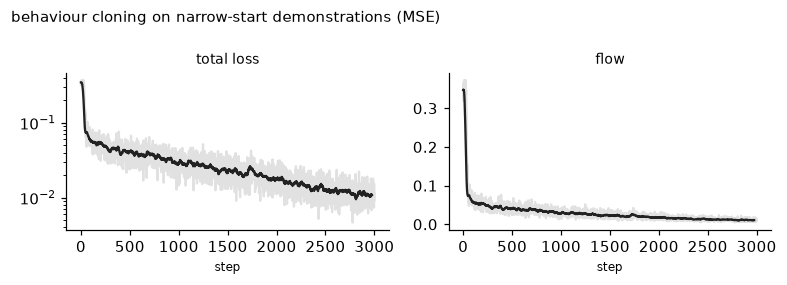

closed-loop success: on starts like the demonstrations 0.86 | on starts anywhere 0.14


In [2]:
rng = np.random.default_rng(0)
narrow = narrow_start_demos(gen, 500, rng, radius=0.1)
bc = new_policy()
tr = PiTrainer(bc, dataset(narrow), batch_size=64, lr=2e-3, grad_clip=10.0); tr.fit(STEPS)
plots.plot_loss(tr.history, keys=("flow",), title="behaviour cloning on narrow-start demonstrations (MSE)")
narrow_scen = [EmbodiedScenario(e.scene, e.task, e.targets[0], "point2d") for e in narrow[:96]]
r_narrow, r_wide = closed_loop(bc, narrow_scen), closed_loop(bc, wide)
print(f"closed-loop success: on starts like the demonstrations {r_narrow.success.mean():.2f} | on starts anywhere {r_wide.success.mean():.2f}")

The same policy that is nearly perfect on the *demonstrated* kind of start fails on most others. Training loss says nothing about this: it was low. Two measurements make the cause visible.

## Step 3: The states the learner visits are not the states it was trained on

First **where** it goes: the positions visited in closed loop against the positions in the demonstrations. Then **how wrong** it is there: for each visited state we ask the expert what it would do (this is the DAgger *oracle*, `expert_episode_from`) and measure `‖π(s) − π*(s)‖`.

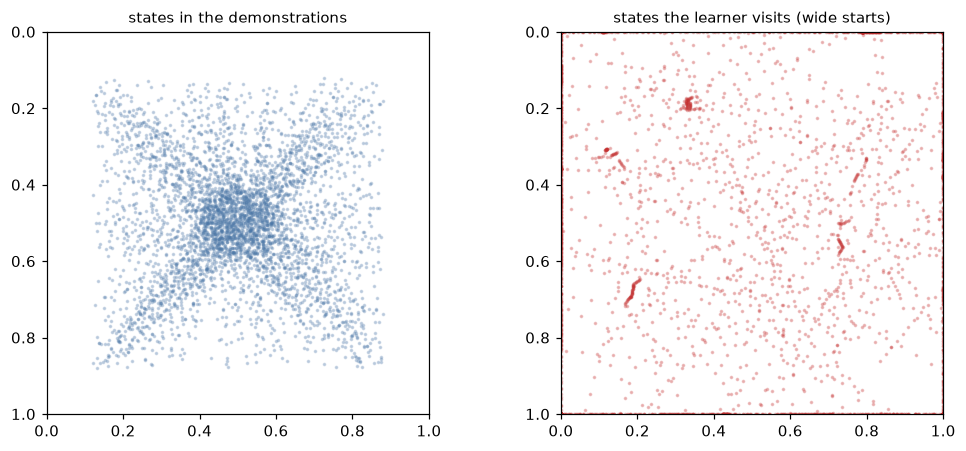

action error |π(s) − π*(s)|: on demonstrated states 0.114 | on the learner's own states 0.729  (an action has length ≈ 0.9)


In [3]:
demo_states = np.concatenate([e.robot[: e.active_steps + 1] for e in narrow])
learner_states = np.concatenate([t[: int(s) + 1] for t, s in zip(r_wide.trajectories, r_wide.steps)])
fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.2))
axes[0].scatter(*demo_states.T, s=2, alpha=0.25, color="#4c78a8"); axes[0].set_title("states in the demonstrations", fontsize=10)
axes[1].scatter(*learner_states.T, s=2, alpha=0.25, color="#c53030"); axes[1].set_title("states the learner visits (wide starts)", fontsize=10)
for ax in axes:
    ax.set_xlim(0, 1); ax.set_ylim(1, 0); ax.set_aspect("equal")
plt.tight_layout(); plt.show()

# offline action error: on demonstrated states vs on the learner's own states
rng2 = np.random.default_rng(1)
demo_idx = [(i, int(rng2.integers(1, max(2, narrow[i].active_steps)))) for i in range(96)]
err_demo = state_action_error(gen, lambda b: bc.sample_actions(b), narrow_scen, [narrow[i].robot[t] for i, t in demo_idx], rng2)
learner_pos = [r_wide.trajectories[i][min(4, int(r_wide.steps[i]))] for i in range(96)]
err_learner = state_action_error(gen, lambda b: bc.sample_actions(b), wide, learner_pos, rng2)
print(f"action error |π(s) − π*(s)|: on demonstrated states {err_demo:.3f} | on the learner's own states {err_learner:.3f}  (an action has length ≈ 0.9)")

The learner visits states (the red cloud) that were never in the demonstrations (the blue disc), and its action error there is many times larger than on the states it was trained on. That is **covariate shift**: the test-time state distribution differs from the training one *because of the learner itself*.

## Step 4: Why the error *compounds*

If the learner errs with probability `ε` per step on the expert's distribution, a mistake puts it in a state the expert never showed, where it errs again, so over a horizon of `T` steps the expected cost grows like **`T² ε`** (Ross et al., 2011), not `T ε`, which is what an i.i.d. supervised learner would suffer. We watch it grow:
the **cross-track error** (distance from the ideal straight line to the target) along the trajectory, for the BC policy and for the expert under the *same* execution noise.

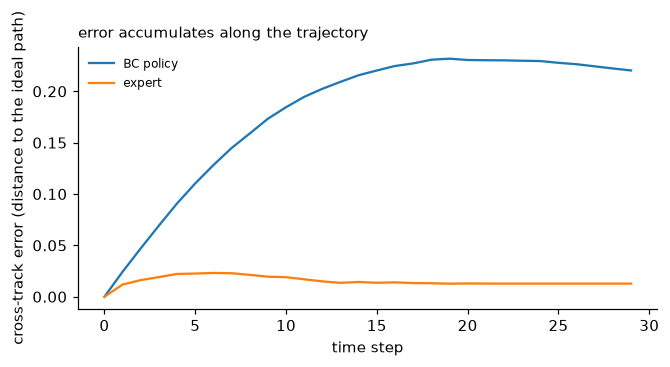

In [4]:
def cross_track(result, scenarios, upto=30):
    out = np.zeros((len(scenarios), upto))
    for i, s in enumerate(scenarios):
        a, b = s.scene.robot, s.scene.objects[s.target]
        d = (b - a) / np.linalg.norm(b - a)
        for t in range(upto):
            p = result.trajectories[i][min(t, len(result.trajectories[i]) - 1)] - a
            out[i, t] = abs(p[0] * d[1] - p[1] * d[0])
    return out.mean(0)
class Expert:                                    # a policy-shaped wrapper around the scripted expert
    def __call__(self, batch):
        out = torch.zeros(batch.size, 1, 4)
        for i, s in enumerate(wide):
            d = s.scene.objects[s.target] - batch.state[i, :2].numpy()
            out[i, 0, :2] = torch.from_numpy(d / max(np.linalg.norm(d), 1e-8) * min(0.9, np.linalg.norm(d) / world.max_step)).float()
        return out
curves = {}
for name, fn in (("BC policy", lambda b: bc.sample_actions(b)), ("expert", Expert())):
    res = ChunkedRunner(world, 1, 1, action_noise=0.3, max_steps=30).run(fn, wide)
    curves[name] = cross_track(res, wide)
plots.curves(list(range(30)), curves, "time step", "cross-track error (distance to the ideal path)", "error accumulates along the trajectory", markers=False)

The expert (same noise) stays close to the straight path: its action at every state is right, so noise is corrected. The BC policy's cross-track error **keeps growing**: each deviation takes it to a state where its own action is worse.

## Step 5: Three fixes

**(a) DAgger** (*Dataset Aggregation*, Ross et al. 2011). Run the **learner**, record the states *it* visits, ask the expert to **relabel** them with the correct action, add them to the dataset, retrain, repeat. The training distribution moves toward the learner's own: the problem the learner will face at test time. Needs an *interactive* expert (a scripted one here; a human or a better policy in practice: this is why DAgger is rare at VLA scale).

**(b) Noise-injected demonstrations** (DART, Laskey et al. 2017). Run the **expert** while random disturbances push the robot, and label the states it is pushed into with the expert's recovery actions: the data then contains *recoveries* with no interactive expert needed during training.

**(c) Action chunking** (ACT). Predict `H` actions per query, so there are `H`-times fewer decisions in which a mistake can compound. (Executed open-loop, a chunk cannot react to noise either: see the chunking notebook.)

We train each on the **same narrow demonstrations** plus its own additional data and evaluate on starts anywhere, with and without execution noise.

In [5]:
train_scen = make_embodied_scenarios(gen, "point2d", 150, seed=7)
results = {"BC (narrow demos)": (closed_loop(bc, wide).success.mean(), closed_loop(bc, wide, noise=0.5).success.mean())}
print("BC (narrow demos)           ", results["BC (narrow demos)"], flush=True)

# (a) DAgger: three rounds
policy, episodes = bc, list(narrow)
dagger_curve = [results["BC (narrow demos)"][0]]
for rnd in range(3):
    new = dagger_episodes(gen, lambda b: policy.sample_actions(b), train_scen, rng, 1, 1, action_noise=0.4, every=2)
    episodes += new
    policy = copy.deepcopy(policy)
    PiTrainer(policy, dataset(episodes), batch_size=64, lr=1e-3, grad_clip=10.0).fit(STEPS // 2)
    dagger_curve.append(closed_loop(policy, wide).success.mean())
    print(f"DAgger round {rnd + 1}: +{len(new):4d} relabelled episodes → success {dagger_curve[-1]:.2f}", flush=True)
results["+ DAgger (3 rounds)"] = (dagger_curve[-1], closed_loop(policy, wide, noise=0.5).success.mean())

# (b) noise-injected expert
perturbed = perturbed_expert_episodes(gen, train_scen, rng, push_prob=0.4, push_size=0.2)
dart = new_policy()
PiTrainer(dart, dataset(narrow + perturbed), batch_size=64, lr=2e-3, grad_clip=10.0).fit(STEPS)
results["+ noise-injected expert (DART)"] = (closed_loop(dart, wide).success.mean(), closed_loop(dart, wide, noise=0.5).success.mean())
print(f"DART: +{len(perturbed)} perturbed episodes →", results["+ noise-injected expert (DART)"], flush=True)

# (c) chunking on the same narrow data
chunked = new_policy(chunk=8)
PiTrainer(chunked, dataset(narrow, chunk=8), batch_size=64, lr=2e-3, grad_clip=10.0).fit(STEPS)
results["+ action chunks (H = 8)"] = (closed_loop(chunked, wide, chunk=8).success.mean(), closed_loop(chunked, wide, chunk=8, noise=0.5).success.mean())

# reference: demonstrations that cover the whole table (what the others try to approximate)
whole = make_reach_demos(gen, 500, np.random.default_rng(3))
upper = new_policy()
PiTrainer(upper, dataset(whole), batch_size=64, lr=2e-3, grad_clip=10.0).fit(STEPS)
results["reference: wide demonstrations"] = (closed_loop(upper, wide).success.mean(), closed_loop(upper, wide, noise=0.5).success.mean())
for k, v in results.items():
    print(f"{k:34s} success {v[0]:.2f} | with execution noise {v[1]:.2f}")

BC (narrow demos)            (np.float64(0.13541666666666666), np.float64(0.13541666666666666))


DAgger round 1: +3011 relabelled episodes → success 0.16


DAgger round 2: +2562 relabelled episodes → success 0.15


DAgger round 3: +1466 relabelled episodes → success 0.19


DART: +1326 perturbed episodes → (np.float64(0.3958333333333333), np.float64(0.46875))


BC (narrow demos)                  success 0.14 | with execution noise 0.14
+ DAgger (3 rounds)                success 0.19 | with execution noise 0.32
+ noise-injected expert (DART)     success 0.40 | with execution noise 0.47
+ action chunks (H = 8)            success 0.19 | with execution noise 0.26
reference: wide demonstrations     success 0.60 | with execution noise 0.70


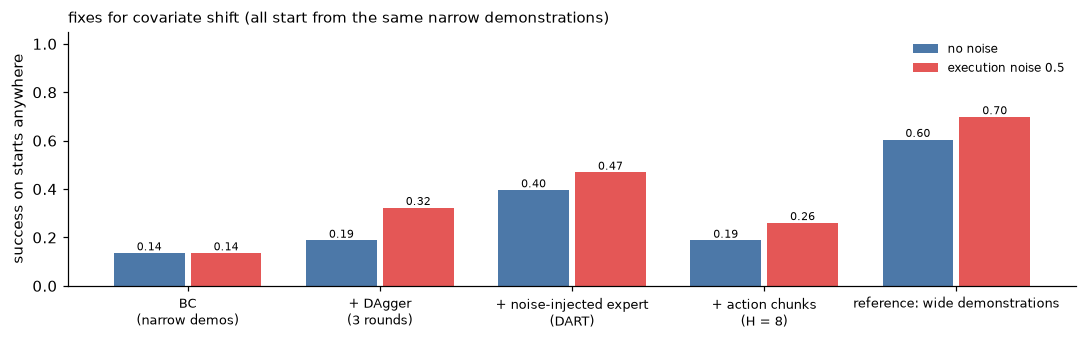

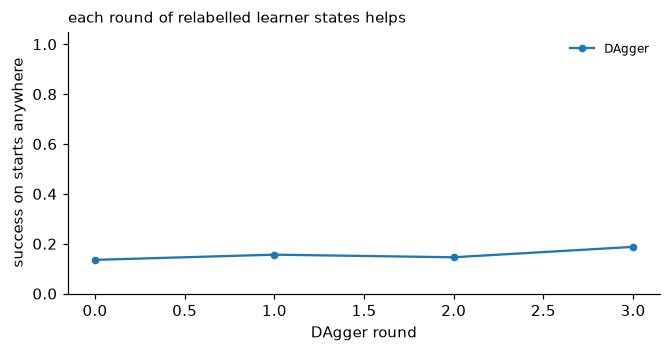

In [6]:
plots.grouped_bars({k.replace(" (", "\n("): {"no noise": v[0], "execution noise 0.5": v[1]} for k, v in results.items()}, "success on starts anywhere", "fixes for covariate shift (all start from the same narrow demonstrations)", colors=["#4c78a8", "#e45756"])
plots.curves(list(range(len(dagger_curve))), {"DAgger": dagger_curve}, "DAgger round", "success on starts anywhere", "each round of relabelled learner states helps", ylim=(0, 1.05))

**What to take from this** (one seed; ± 8 points is noise, and the policy itself is weak: even with wide demonstrations it reaches only 0.60 at this budget).

* The BC policy trained on the narrow slice succeeds on **0.86** of the starts it was shown and **0.14** of the others; its action error is **0.11 on the demonstrated states and 0.73 on its own**.
* **Noise-injected demonstrations (DART) helped most** (0.40, and 0.47 under execution noise): the pushes put the *expert* in off-distribution states and the relabelled data contains recoveries, without needing an interactive expert at training time. **DAgger moved the needle much less in this run** (0.16 → 0.15 → 0.19; 0.32 with execution noise): the learner's own mistakes are *systematic*, which is what DAgger is meant to exploit, but with 1500-step
  updates on a dataset dominated by earlier rounds the gain was small and unreliable (an earlier, similar run reached 0.38 after three rounds: that spread is the noise level). So the theory (DAgger removes the covariate shift) holds, but **the amount of retraining and the relabelling budget decide whether you see it**.
* **Chunking alone did not fix it** (0.19): the chunk policy has still never seen those states. Its value is fewer decisions, not coverage (see the chunking notebook).
* The reference trained on demonstrations that **cover the table** is the best (0.60, 0.70 with noise), which is the point: **coverage of the test distribution is the first-order fix**; DART and DAgger approximate it by *generating the missing coverage*.
In practice VLA teams rely on (i) **diverse data** (many scenes, start states), (ii) **chunking**, (iii) **augmentation**, and occasionally **human-in-the-loop corrections** (a DAgger-like loop). Pure interactive DAgger is rare at VLA scale because it needs an expert online.

# Part 2: Pre-training and data scale

## Step 6: What does pre-training buy? Success vs number of demonstrations

The "standard 2026 recipe" starts from a pre-trained VLM. To see what that is worth we train the same policy with **N** demonstrations (wide starts), N from 10 to 1000, and compare a policy built on the **VQA-pre-trained** (frozen) VLM with one whose VLM is **random** and trained end-to-end (the "from scratch" ablation of RT-2).

N =    10: pre-trained VLM… frozen (+ action expert) 0.07 | pre-trained VLM… fine-tuned 0.00 | random VLM… trained from scratch 0.04


N =    30: pre-trained VLM… frozen (+ action expert) 0.07 | pre-trained VLM… fine-tuned 0.05 | random VLM… trained from scratch 0.01


N =   100: pre-trained VLM… frozen (+ action expert) 0.14 | pre-trained VLM… fine-tuned 0.12 | random VLM… trained from scratch 0.03


N =   300: pre-trained VLM… frozen (+ action expert) 0.59 | pre-trained VLM… fine-tuned 0.47 | random VLM… trained from scratch 0.15


N =  1000: pre-trained VLM… frozen (+ action expert) 0.74 | pre-trained VLM… fine-tuned 1.00 | random VLM… trained from scratch 1.00


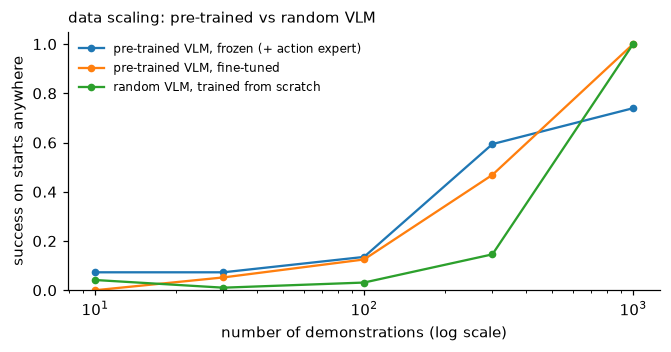

In [7]:
sizes = [10, 30, 100, 300, 1000]
scale_results = {"pre-trained VLM, frozen (+ action expert)": [], "pre-trained VLM, fine-tuned": [], "random VLM, trained from scratch": []}
for n in sizes:
    demos = make_reach_demos(gen, n, np.random.default_rng(10 + n))
    for name in scale_results:
        if name.startswith("pre-trained VLM, frozen"):
            p = new_policy()
        elif name.startswith("pre-trained VLM, fine-tuned"):
            p = new_policy(frozen=False)
        else:
            p = new_policy(frozen=False, vlm_init=ToyVLM(VLMConfig(), vocab))
        PiTrainer(p, dataset(demos), batch_size=min(64, max(8, n)), lr=2e-3, grad_clip=10.0).fit(2500)
        scale_results[name].append(closed_loop(p, wide).success.mean())
    print(f"N = {n:5d}: " + " | ".join(f"{k.split(',')[0][:22]}…{k.split(',')[-1]} {v[-1]:.2f}" for k, v in scale_results.items()), flush=True)
plots.curves(sizes, scale_results, "number of demonstrations (log scale)", "success on starts anywhere", "data scaling: pre-trained vs random VLM", logx=True, ylim=(0, 1.05))

**Reading the curves** (one seed per point; a model trained for a fixed 2500 steps):

* **Success rises with data and saturates** (the usual log-like gain): from ≈ 0.1 at 100 demonstrations to ≈ 1.0 at 1000 for the end-to-end models.
* **Pre-training matters in the middle of the range**: at 300 demonstrations the pre-trained models reach **0.59 (frozen VLM) and 0.47 (fine-tuned)** against **0.15 for a random VLM**; its features already say "where is the red thing" so far fewer demonstrations are needed. At 10-100 demonstrations nothing works yet in this budget (all ≤ 0.14), and at 1000 the end-to-end models (pre-trained *or* random) are perfect (1.00): enough data lets the
  random model learn those features itself, which is the "gap narrows" part of the usual story.
* **A frozen backbone caps what can be learned**: at 1000 demonstrations the frozen-VLM policy saturates at 0.74 while the fine-tuned model reaches 1.00 (the price of freezing: SmolVLA's choice is made for compute and for *keeping* the VLM's knowledge).
Note what pre-training does **not** do: a VLM pre-trained on web data was never asked to produce actions; the *robot* data teaches that.

## Step 7: Co-training and forgetting (where this fits)

Fine-tuning a VLM on robot data alone makes it **forget** its web knowledge (catastrophic forgetting). The two remedies are **co-training** (RT-2: mix web vision-language data into every batch) and **replay** (mix old robot data back in). Both were measured in other notebooks:
`vlm_backbone_step_by_step.ipynb` (Step 7: from scratch vs fine-tune vs **co-fine-tune** on language generalisation) and `finetuning_methods_step_by_step.ipynb` (Step 5: **replay** beat every parameter-efficient method on forgetting). The training mixture is a design decision as important as the architecture.

# Part 3: Data quality, scale and reality

## Step 8: Is the bottleneck the amount of data or its quality?

BC copies whatever it is shown. Our generator has demonstrations of different **styles**: `expert` (straight, fast), `sloppy` (wobbling, slow) and `mistake` (first heads for a *wrong* object, then corrects). We train on 300 expert demonstrations, then on 300 expert + 300 demonstrations of a worse style, and on a mixture of all.

300 expert                                 success 0.47 (seeds: 0.43, 0.51) | steps when successful 14.9


300 expert + 300 sloppy                    success 0.49 (seeds: 0.39, 0.59) | steps when successful 18.9


300 expert + 300 mistake                   success 0.32 (seeds: 0.33, 0.30) | steps when successful 19.5


300 expert + 300 of every other style      success 0.42 (seeds: 0.46, 0.39) | steps when successful 19.2


600 expert (more data, same quality)       success 0.52 (seeds: 0.44, 0.59) | steps when successful 14.3


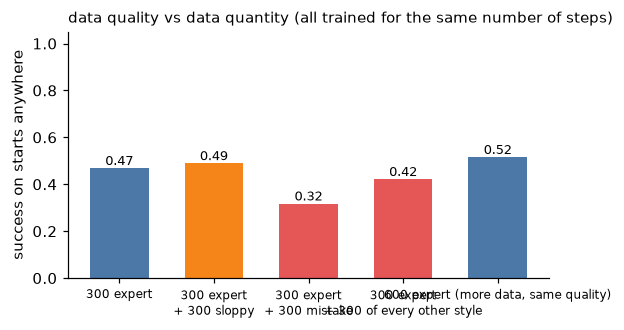

In [8]:
def styled(style, n, seed):
    rng = np.random.default_rng(seed)
    return [gen.demo("reach", rng, style, task=gen.sample_task("reach", rng, num_objects=2)) for _ in range(n)]
expert_300 = styled("expert", 300, 21)
sets = {"300 expert": expert_300, "300 expert + 300 sloppy": expert_300 + styled("sloppy", 300, 22), "300 expert + 300 mistake": expert_300 + styled("mistake", 300, 23),
        "300 expert + 300 of every other style": expert_300 + styled("careful", 100, 24) + styled("sloppy", 100, 25) + styled("mistake", 100, 26), "600 expert (more data, same quality)": expert_300 + styled("expert", 300, 27)}
quality = {}
for name, eps in sets.items():
    runs = []
    for seed in (0, 1):                           # two training seeds: single runs of this kind differ by ±0.1
        torch.manual_seed(seed)
        p = SmolVLAPolicy(vlm, SmolVLAConfig(chunk_size=1, objective="mse"))
        PiTrainer(p, dataset(eps), batch_size=64, lr=2e-3, grad_clip=10.0, seed=seed).fit(STEPS)
        r = closed_loop(p, wide)
        runs.append((r.success.mean(), float(np.nanmean(r.steps[r.success])) if r.success.any() else float("nan")))
    quality[name] = tuple(np.nanmean(runs, axis=0))
    print(f"{name:42s} success {quality[name][0]:.2f} (seeds: {runs[0][0]:.2f}, {runs[1][0]:.2f}) | steps when successful {quality[name][1]:.1f}", flush=True)
plots.bar_compare({k.replace(" + ", "\n+ "): v[0] for k, v in quality.items()}, "success on starts anywhere", "data quality vs data quantity (all trained for the same number of steps)", ylim=(0, 1.05), colors=["#4c78a8", "#f58518", "#e45756", "#e45756", "#4c78a8"], rotate=0)

**What to take from this** (two seeds per row; the seeds differ by up to 0.2, so only large effects count).

* **Mistake demonstrations clearly hurt**: adding 300 `mistake` demonstrations (which head for the *wrong* object in exactly the states where the expert heads for the right one) drops success from 0.47 to **0.32**: BC averages right and wrong.
* **Sloppy demonstrations did not reduce success** (0.49) but made the policy **slower** (18.9 steps to succeed vs 14.9): it imitates the wobble.
* **More data of the same quality (600 expert, 0.52)** is not significantly better than 300 (0.47) at this size: the gain from data is real but needs *more* than a doubling to show above the noise.
* The mixture of all styles (0.42) sits in between. This is why **curation matters as much as scale**, and why π0.7 conditions on *episode metadata* (quality, speed, whether a mistake occurs) so that bad data can still be used *without* being imitated (`pi_family` notebooks).

## Step 9: The data reality (from the papers)

| model | pre-training data | fine-tuning data |
|---|---|---|
| RT-1 | ≈ 130K episodes, 13 robots, 17 months | (trained from scratch on that set) |
| RT-2 | the RT-1 set + web vision-language data (co-fine-tuning) | none (zero-shot generalisation) |
| Octo | ≈ 800K episodes from Open X-Embodiment | tens to hundreds of demonstrations |
| OpenVLA | ≈ 970K episodes from Open X-Embodiment | ≈ 10-150 demonstrations per task (LoRA) |
| π0 | ≈ 10K hours of robot data (7 robot configurations) + OXE | 1-20 hours per task |
| GR00T N1 | real robot + human video + synthetic (simulation) data | post-training on a few demonstrations per embodiment |

**Open X-Embodiment** is a collaboration of 21 institutions that pooled 60 existing datasets: **22 robot embodiments, > 1M trajectories, 527 skills**. Its coverage is **skewed**: mostly single-arm tabletop manipulation with parallel-jaw grippers (Franka, WidowX, Google robot), gripper-centric skills (pick, place, push, open, close), short horizons, and few **bimanual, dexterous-hand, deformable-object, contact-rich or long-horizon** tasks;
and the **action spaces** differ across datasets (hence the normalisation / per-embodiment heads of the cross-embodiment notebooks). *Data, not architecture*, is the dominant scaling axis for VLAs: π0 and OpenVLA both fine-tune the same recipe on very different amounts of data and the gaps follow the data.

**Take-aways.** (1) BC = maximum-likelihood imitation; trained on the expert's states, deployed on the learner's. (2) The mismatch (**covariate shift**) makes errors **compound** (`T² ε`). (3) Fixes: **cover** the test distribution (diverse data), **relabel the learner's states** (DAgger), **add recoveries** (noise injection), **fewer decisions** (chunking), **augmentation**. (4) Pre-training matters most when **data is scarce**; the gap narrows as data grows.
(5) **Quality ≥ quantity**: bad demonstrations are imitated too.

### 🧪 Exercises
1. Vary the start radius of the narrow demonstrations (0.05, 0.2, 0.4): how does the BC success and the gap in Step 3 change?
2. Run DAgger with `action_noise = 0` for the rollouts: does exploration noise help the learner reach informative states faster?
3. Add **image augmentation** (random brightness / small shifts) to `dataset(...)` and test under the appearance shift of `vlm_backbone_step_by_step.ipynb`.
4. In Step 6 extend N to 3000 and fit `success = 1 − a·N^{-b}`: does the pre-trained VLM change `a` or `b`?
5. Use π0.7-style **metadata conditioning** (quality as an input) on the mixed-quality set of Step 8 and test with `quality = 5`.